# Exercise 1: Compare NumPy and CuPy transfer paths

## Question

For this PyMUST raw-RF workload and the same CUDA beamformer, does the CuPy path reduce latency compared with passing NumPy arrays from the CPU?

## Hypothesis

Both modes use the CUDA beamformer in `mach`. I expect lower prepared per-ensemble latency from CuPy because it keeps geometry on the GPU, uploads each IQ ensemble, and performs Power Doppler reduction there. NumPy passes host arrays to `mach`; the wrapper stages them for CUDA and returns beamformed output to the CPU for reduction. I expect matching Power Doppler maps within floating-point tolerance.

This is an end-to-end data-placement comparison, not a comparison of the CUDA kernels or an isolated transfer benchmark.

## Paths compared

| Stage | NumPy host arrays | CuPy GPU-resident |
|---|---|---|
| RF → IQ | CPU, before timing | CPU, before timing |
| IQ and geometry | Host arrays passed to `mach` for CUDA staging | Geometry copied during setup and reused; each call uploads IQ |
| Beamforming | Same CUDA beamformer in `mach` | Same CUDA beamformer in `mach` |
| Power Doppler reduction | CPU, after output returns to host | GPU; only the final map returns to host |

Geometry means receiver positions, scan-grid positions, and transmit arrival times. CuPy prepares these arrays once per process and scan configuration. NumPy passes host arrays to `mach`, whose [Python wrapper](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/kernel.py#L208-L285) and [CUDA binding](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/kernel.cu#L1073-L1215) show how host inputs and outputs are handled.

The benchmark repeats one preconverted 32-frame IQ block to measure latency variation; it does not replay 200 distinct acquisitions. CuPy uploads IQ on every call, while prepared geometry stays resident. A live stream would convert each new RF ensemble to IQ on the CPU and upload that new IQ block.

The input is a rotating-disk tissue-mimicking phantom, not a brain fUSI recording. These measurements do not include a live acquisition queue or capture-to-display latency.

## Procedure

Run both modes on the same Colab T4, dataset, grid, and batch size. Check input fingerprints and output maps before comparing times. Report the warmed latency distribution and one cold first-result observation per mode. Use Nsight Systems on a fixed Linux NVIDIA instance to inspect transfer and synchronization costs.

This run uses a 251 × 251 grid, batch size 32, 10 warmups, and 200 measured calls per mode. The short smoke check is separate.


## Prepare the Colab runtime

Connect this notebook to the Colab T4 kernel in VS Code. In the Colab terminal, update the project checkout from GitHub:

```bash
cd /content/realtime-beamforming-lab && git pull --ff-only origin main
```

The terminal and notebook kernel share the T4 runtime. The next cell checks that the checkout is present.


In [ ]:
from pathlib import Path
import os

repo = Path("/content/realtime-beamforming-lab")
assert (repo / "pyproject.toml").is_file(), (
    f"Clone the GitHub repository into Colab at {repo}"
)
assert (repo / "src/beamforming_lab/benchmark.py").is_file(), "The GitHub checkout is incomplete"
os.chdir(repo)
print(f"Using checkout: {repo}")


In [ ]:
!nvidia-smi


## Install the Colab GPU dependencies

Run this once in a fresh runtime. It removes conflicting CuPy wheels and installs the project with its Colab GPU dependencies. Restart the notebook kernel after installation, then run the checks below before benchmarking.


In [ ]:
%pip uninstall -y cupy-cuda12x cupy-cuda13x
%pip install --no-cache-dir -e '.[gpu-colab]'


In [ ]:
from pathlib import Path
import importlib.metadata as metadata
import os
import cupy as cp

repo = Path("/content/realtime-beamforming-lab")
assert (repo / "pyproject.toml").is_file(), "The GitHub checkout is missing after kernel restart"
os.chdir(repo)
cupy_wheels = sorted(
    dist.metadata.get("Name", "")
    for dist in metadata.distributions()
    if dist.metadata.get("Name", "").lower().startswith("cupy-cuda")
)
print("CuPy module:", cp.__file__)
print("CuPy wheels:", cupy_wheels)
print("CUDA devices:", cp.cuda.runtime.getDeviceCount())
print("CUDA runtime:", cp.cuda.runtime.runtimeGetVersion())
assert cp.cuda.runtime.getDeviceCount() > 0
assert len(cupy_wheels) == 1 and cupy_wheels[0].lower() == "cupy-cuda13x", cupy_wheels
cp.cuda.Device().synchronize()


## Fix the comparison conditions

Each mode gets one cold first call, 10 warmups, and 200 timed calls on the same preconverted IQ block. Both use the same 251 × 251 grid and 32-frame batch. Repeating a fixed input controls the workload; CuPy still uploads IQ on every call, while its geometry remains available for later calls in the same process.

Reports are saved in `results/`. Power Doppler maps are saved in `artifacts/` for the output comparison.


In [ ]:
from pathlib import Path

RUNS = 200
WARMUP = 10
BATCH_SIZE = 32
GRID_SIZE = 251

results_dir = repo / "results"
artifacts_dir = repo / "artifacts"
results_dir.mkdir(exist_ok=True)
artifacts_dir.mkdir(exist_ok=True)

report_paths = {
    "numpy": results_dir / "exercise1-pymust-numpy.json",
    "cupy": results_dir / "exercise1-pymust-cupy.json",
}
power_paths = {
    "numpy": artifacts_dir / "exercise1-pymust-numpy-power.npy",
    "cupy": artifacts_dir / "exercise1-pymust-cupy-power.npy",
}
print(f"Conditions: {RUNS} measured runs, {WARMUP} warmups, batch size {BATCH_SIZE}, grid {GRID_SIZE} × {GRID_SIZE}")


## Run the matched benchmarks

Each command starts a fresh `beamform-lab` process from the same dataset. The cold measurement runs before warmups and records setup through the first Power Doppler map. The steady-state timer then covers 10 warmups and 200 measured calls.

The pipeline timer includes `mach` staging and output handling plus Power Doppler reduction. NumPy reduces on the CPU. CuPy uploads IQ on each call, reduces on the GPU, and copies back the final map. CPU RF-to-IQ is measured once outside this loop and is added only to the first-sample estimate. The explicit upload timer measures only CuPy IQ upload; NumPy's internal transfers are not isolated.

The two separate processes give NumPy and CuPy fresh process-level CUDA contexts. This cell takes longer than the smoke check because it measures 400 calls, 20 warmups, and one cold call per mode.


In [11]:
import json
import subprocess

for mode in ("numpy", "cupy"):
    command = [
        "beamform-lab", "benchmark",
        "--dataset", "pymust",
        "--mode", mode,
        "--measure-cold-start",
        "--runs", str(RUNS),
        "--warmup", str(WARMUP),
        "--batch-size", str(BATCH_SIZE),
        "--grid-size", str(GRID_SIZE),
        "--output", str(report_paths[mode]),
        "--save-power", str(power_paths[mode]),
    ]
    print("\nRunning:", " ".join(command), flush=True)
    completed = subprocess.run(command, cwd=repo, text=True, capture_output=True)
    if completed.returncode:
        print(completed.stdout[-4000:])
        print(completed.stderr[-4000:])
        completed.check_returncode()
    report = json.loads(report_paths[mode].read_text())
    pipeline = report["ensemble_pipeline_wall_ms"]
    first_sample = report["first_sample_to_output_ms"]
    cold = report["cold_start_measurement"]
    print(
        f"{mode}: GPU={report['runtime_provenance']['gpu']['name']}; "
        f"pipeline p50={pipeline['p50']:.2f} ms, p95={pipeline['p95']:.2f} ms; "
        f"warm first-sample estimate p50={first_sample['p50']:.2f} ms; "
        f"cold setup + first ensemble={cold['device_setup_plus_first_ensemble_wall_ms']:.2f} ms; "
        f"cold first-sample estimate={cold['first_sample_to_output_ms']:.2f} ms; "
        f"report={report_paths[mode].name}"
    )



Running: beamform-lab benchmark --dataset pymust --mode numpy --measure-cold-start --runs 200 --warmup 10 --batch-size 32 --grid-size 251 --output /content/realtime-beamforming-lab/results/exercise1-pymust-numpy.json --save-power /content/realtime-beamforming-lab/artifacts/exercise1-pymust-numpy-power.npy
numpy: GPU=Tesla T4; pipeline p50=16.20 ms, p95=19.24 ms; warm first-sample estimate p50=278.74 ms; cold setup + first ensemble=198.58 ms; cold first-sample estimate=461.12 ms; report=exercise1-pymust-numpy.json

Running: beamform-lab benchmark --dataset pymust --mode cupy --measure-cold-start --runs 200 --warmup 10 --batch-size 32 --grid-size 251 --output /content/realtime-beamforming-lab/results/exercise1-pymust-cupy.json --save-power /content/realtime-beamforming-lab/artifacts/exercise1-pymust-cupy-power.npy
cupy: GPU=Tesla T4; pipeline p50=4.71 ms, p95=6.16 ms; warm first-sample estimate p50=250.35 ms; cold setup + first ensemble=395.38 ms; cold first-sample estimate=641.02 ms; r

## Check the pair, then compare outputs

Confirm both reports used the same RF fingerprint, grid, batch size, run counts, and GPU. Then compare the Power Doppler maps. Small floating-point differences are expected; the check does not require bitwise equality.


In [12]:
import json
import numpy as np

reports = {mode: json.loads(report_paths[mode].read_text()) for mode in ("numpy", "cupy")}
power_maps = {mode: np.load(power_paths[mode]) for mode in ("numpy", "cupy")}

numpy_report, cupy_report = reports["numpy"], reports["cupy"]
assert numpy_report["data_provenance"]["rf_array_sha256"] == cupy_report["data_provenance"]["rf_array_sha256"]
assert numpy_report["scan_grid_points"] == cupy_report["scan_grid_points"]
assert numpy_report["batch_size_frames"] == cupy_report["batch_size_frames"] == BATCH_SIZE
assert numpy_report["measurement_runs"] == cupy_report["measurement_runs"] == RUNS
assert numpy_report["warmup_runs"] == cupy_report["warmup_runs"] == WARMUP
assert numpy_report["runtime_provenance"]["gpu"]["name"] == cupy_report["runtime_provenance"]["gpu"]["name"]
assert power_maps["numpy"].shape == power_maps["cupy"].shape

numpy_map = power_maps["numpy"].astype(np.float64)
cupy_map = power_maps["cupy"].astype(np.float64)
difference = cupy_map - numpy_map
scale = max(float(np.linalg.norm(numpy_map.ravel())), np.finfo(np.float64).tiny)
relative_l2_error = float(np.linalg.norm(difference.ravel()) / scale)
shared_peak = max(float(np.max(numpy_map)), float(np.max(cupy_map)), np.finfo(np.float64).tiny)
max_abs_error = float(np.max(np.abs(difference)))
peak_relative_error = max_abs_error / shared_peak
correlation = float(np.corrcoef(numpy_map.ravel(), cupy_map.ravel())[0, 1])

print(f"Output shape: {numpy_map.shape}")
print(f"Mean Power Doppler feature — NumPy: {numpy_report['mean_output_feature']:.6g}; CuPy: {cupy_report['mean_output_feature']:.6g}")
print(f"Normalized L2 map error: {relative_l2_error:.3e}")
print(f"Maximum absolute map error: {max_abs_error:.6g} ({peak_relative_error:.3e} of shared peak)")
print(f"Pixel-wise map correlation: {correlation:.8f}")

print("\nTiming context:")
for mode in ("numpy", "cupy"):
    report = reports[mode]
    print(f"{mode}: RF-to-IQ once={report['rf_to_iq_ms_once']:.2f} ms; "
          f"explicit geometry upload once={report['static_geometry_upload_ms_once']:.2f} ms")
cupy_upload = reports["cupy"]["per_ensemble_input_upload_ms"]
print(f"CuPy explicit IQ upload: p50={cupy_upload['p50']:.2f} ms, p95={cupy_upload['p95']:.2f} ms per ensemble")
print("NumPy host-array transfers are handled inside mach and are not isolated by this upload timer.")


Output shape: (251, 251)
Mean Power Doppler feature — NumPy: 7.12192e+08; CuPy: 7.12192e+08
Normalized L2 map error: 5.865e-08
Maximum absolute map error: 1024 (1.405e-07 of shared peak)
Pixel-wise map correlation: 1.00000000

Timing context:
numpy: RF-to-IQ once=259.34 ms; explicit geometry upload once=0.00 ms
cupy: RF-to-IQ once=242.44 ms; explicit geometry upload once=172.30 ms
CuPy explicit IQ upload: p50=1.82 ms, p95=2.01 ms per ensemble
NumPy host-array transfers are handled inside mach and are not isolated by this upload timer.


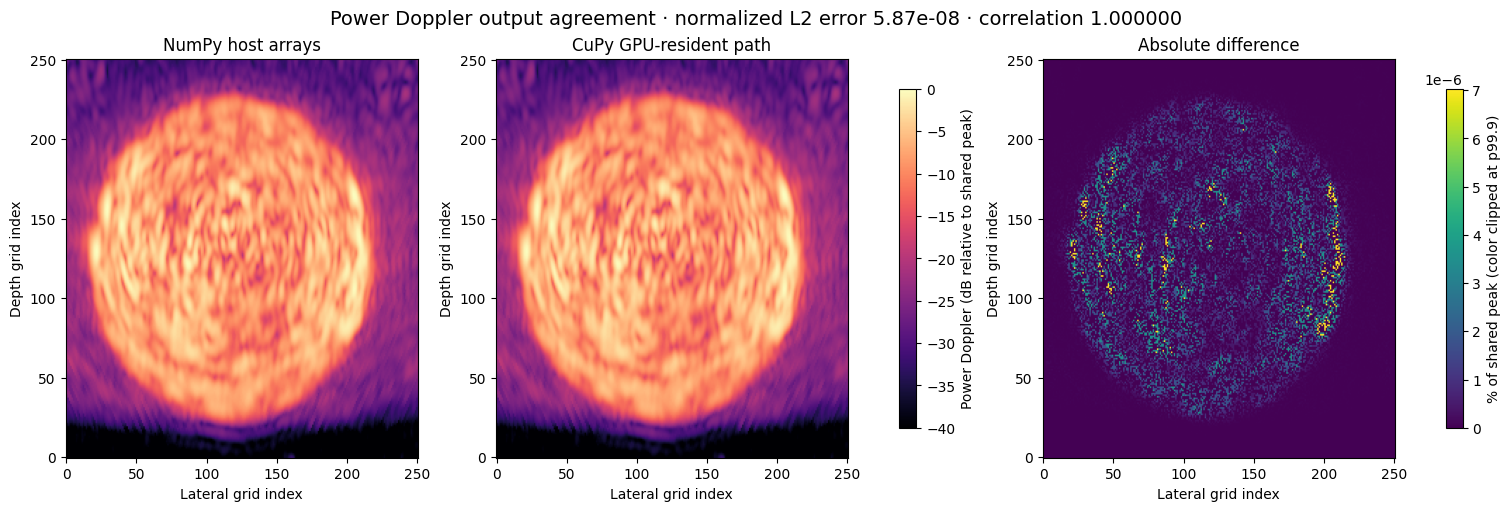

Saved /content/realtime-beamforming-lab/results/exercise1-pymust-output-comparison.png


In [13]:
import matplotlib.pyplot as plt

shared_peak = max(float(np.max(numpy_map)), float(np.max(cupy_map)), np.finfo(np.float64).tiny)
floor = 1e-4
numpy_db = 10 * np.log10(np.maximum(numpy_map / shared_peak, floor))
cupy_db = 10 * np.log10(np.maximum(cupy_map / shared_peak, floor))
abs_difference_percent = 100 * np.abs(difference) / shared_peak
diff_vmax = max(float(np.percentile(abs_difference_percent, 99.9)), 1e-6)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for ax, image, title in [
    (axes[0], numpy_db, "NumPy host arrays"),
    (axes[1], cupy_db, "CuPy GPU-resident path"),
]:
    view = ax.imshow(image.T, origin="lower", cmap="magma", vmin=-40, vmax=0, aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("Lateral grid index")
    ax.set_ylabel("Depth grid index")
fig.colorbar(view, ax=axes[:2], label="Power Doppler (dB relative to shared peak)", shrink=0.85)

error_view = axes[2].imshow(
    abs_difference_percent.T, origin="lower", cmap="viridis", vmin=0, vmax=diff_vmax, aspect="auto"
)
axes[2].set_title("Absolute difference")
axes[2].set_xlabel("Lateral grid index")
axes[2].set_ylabel("Depth grid index")
fig.colorbar(error_view, ax=axes[2], label="% of shared peak (color clipped at p99.9)", shrink=0.85)
fig.suptitle(
    f"Power Doppler output agreement · normalized L2 error {relative_l2_error:.2e} · correlation {correlation:.6f}",
    fontsize=14,
)
output_plot_path = results_dir / "exercise1-pymust-output-comparison.png"
fig.savefig(output_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {output_plot_path}")


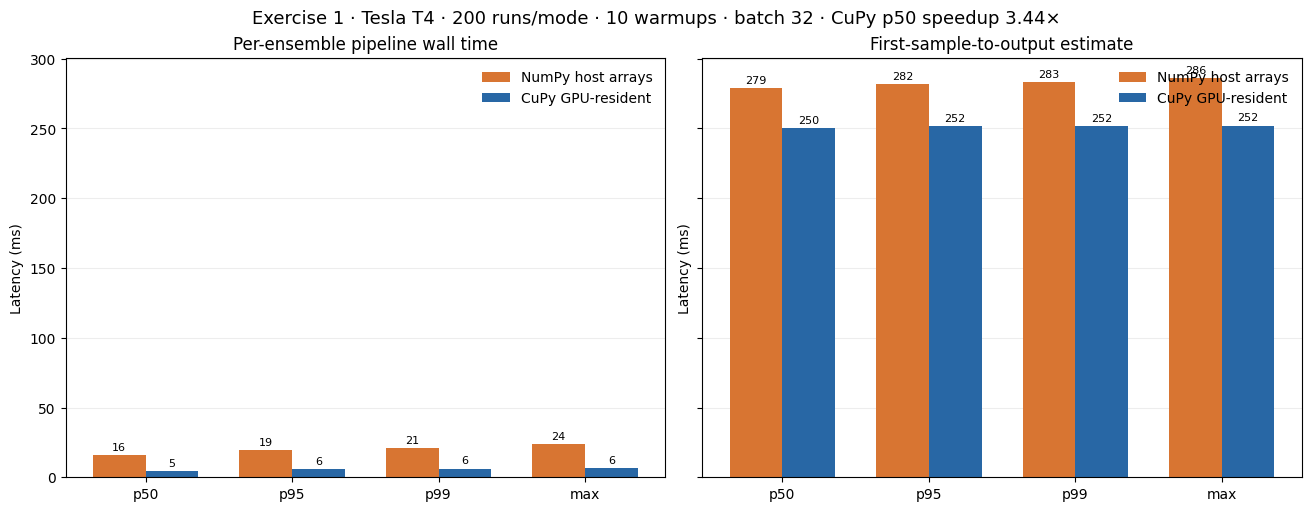

Saved /content/realtime-beamforming-lab/results/exercise1-pymust-latency-comparison.png
Ensemble p50: NumPy 16.20 ms; CuPy 4.71 ms; NumPy/CuPy ratio 3.44×


In [14]:
import matplotlib.pyplot as plt
import numpy as np

percentiles = ("p50", "p95", "p99", "max")
mode_labels = {"numpy": "NumPy host arrays", "cupy": "CuPy GPU-resident"}
colors = {"numpy": "#D87532", "cupy": "#2867A5"}
metric_specs = [
    ("ensemble_pipeline_wall_ms", "Per-ensemble pipeline wall time"),
    ("first_sample_to_output_ms", "First-sample-to-output estimate"),
]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, constrained_layout=True)
x = np.arange(len(percentiles))
width = 0.36
for ax, (metric_key, title) in zip(axes, metric_specs):
    for offset, mode in ((-width / 2, "numpy"), (width / 2, "cupy")):
        values = [reports[mode][metric_key][key] for key in percentiles]
        bars = ax.bar(x + offset, values, width, label=mode_labels[mode], color=colors[mode])
        ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=8)
    ax.set_title(title)
    ax.set_xticks(x, percentiles)
    ax.set_ylabel("Latency (ms)")
    ax.grid(axis="y", alpha=0.22)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)

numpy_p50 = reports["numpy"]["ensemble_pipeline_wall_ms"]["p50"]
cupy_p50 = reports["cupy"]["ensemble_pipeline_wall_ms"]["p50"]
cupy_speedup = numpy_p50 / cupy_p50 if cupy_p50 else float("nan")
gpu_name = reports["cupy"]["runtime_provenance"]["gpu"]["name"]
fig.suptitle(
    f"Exercise 1 · {gpu_name} · {RUNS} runs/mode · {WARMUP} warmups · batch {BATCH_SIZE} · CuPy p50 speedup {cupy_speedup:.2f}×",
    fontsize=13,
)
timing_plot_path = results_dir / "exercise1-pymust-latency-comparison.png"
fig.savefig(timing_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {timing_plot_path}")
print(f"Ensemble p50: NumPy {numpy_p50:.2f} ms; CuPy {cupy_p50:.2f} ms; NumPy/CuPy ratio {cupy_speedup:.2f}×")


### Cold start versus prepared first-sample estimate

The cold timer starts before geometry preparation and ends when the first Power Doppler map is ready. It includes first CUDA use in both modes: inside the first `mach` call for NumPy and during CuPy geometry preparation for CuPy.

The first-sample estimate adds one CPU RF-to-IQ measurement and a 3.2 ms acquisition window estimated from frame count and PRF. The warm estimate uses pipeline p50 and assumes CUDA and CuPy geometry are ready. There is one cold observation per mode; neither estimate measures live capture-to-display latency.


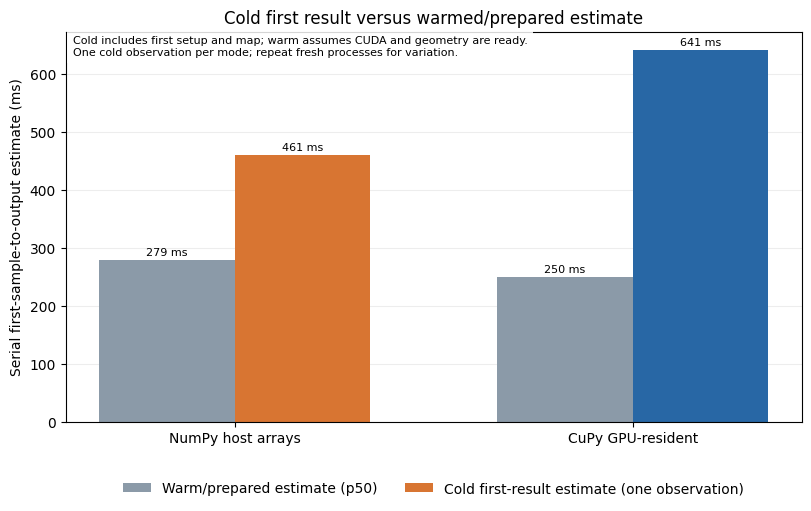

Saved /content/realtime-beamforming-lab/results/exercise1-pymust-cold-start.png


In [16]:
import matplotlib.pyplot as plt
import numpy as np

modes = ("numpy", "cupy")
labels = {"numpy": "NumPy host arrays", "cupy": "CuPy GPU-resident"}
colors = {"numpy": "#D87532", "cupy": "#2867A5"}
if not all(reports[mode].get("cold_start_measurement") is not None for mode in modes):
    raise RuntimeError("Rerun both benchmark commands with --measure-cold-start before plotting.")

warm_estimates = [
    reports[mode]["first_sample_to_output_ms"]["p50"] for mode in modes
]
cold_estimates = [
    reports[mode]["cold_start_measurement"]["first_sample_to_output_ms"]
    for mode in modes
]
x = np.arange(len(modes))
width = 0.34
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
warm_bars = ax.bar(
    x - width / 2,
    warm_estimates,
    width,
    label="Warm/prepared estimate (p50)",
    color="#8B9AA8",
)
cold_bars = ax.bar(
    x + width / 2,
    cold_estimates,
    width,
    label="Cold first-result estimate (one observation)",
    color=[colors[mode] for mode in modes],
)
ax.bar_label(warm_bars, fmt="%.0f ms", padding=2, fontsize=8)
ax.bar_label(cold_bars, fmt="%.0f ms", padding=2, fontsize=8)
ax.set_xticks(x, [labels[mode] for mode in modes])
ax.set_ylabel("Estimated first-sample-to-output latency (ms)")
ax.set_title("Estimated time to first output: cold vs prepared")
ax.grid(axis="y", alpha=0.22)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.text(
    0.01,
    0.99,
    "Both add CPU RF→IQ and estimated 3.2 ms acquisition. Cold includes setup + map.\n"
    "One cold observation per mode; repeat fresh processes for variation.",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=8,
    bbox={"facecolor": "white", "alpha": 0.84, "edgecolor": "none"},
)
plot_path = results_dir / "exercise1-pymust-cold-start.png"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {plot_path}")


## Results from this T4 run

The runs used the same Tesla T4, RF fingerprint, 251 × 251 grid, and batch size 32. Each mode had 10 warmups and 200 measured calls. Their 251 × 251 Power Doppler maps agree closely: normalized L2 error `5.87 × 10⁻⁸`, correlation effectively `1.0`, and maximum difference `1.4 × 10⁻⁷` of the shared peak.

| Measurement | NumPy | CuPy |
|---|---:|---:|
| Warm pipeline p50 / p95 | 16.20 / 19.24 ms | 4.71 / 6.16 ms |
| Cold setup + first ensemble | 198.58 ms | 395.38 ms |
| Cold first-sample estimate | 461.12 ms | 641.02 ms |

For this run, prepared CuPy pipeline latency was 3.44× faster at p50 and 3.12× faster at p95. The measured CuPy IQ upload was 1.82 ms at p50 per call. CuPy geometry preparation took 322.47 ms; the explicit geometry upload timer accounted for 172.30 ms of that interval. Preparation also includes first-use runtime and allocation work, so these values do not isolate geometry-copy cost.

The cold comparison reverses: CuPy's first-sample estimate was 179.90 ms slower. Its setup plus first ensemble cost about 197 ms more, while prepared p50 saves about 11.5 ms per call. This is a startup-versus-warmed-latency tradeoff in one process-level run, not a general break-even result. Geometry can be reused while the process and scan configuration remain fixed; every new CuPy IQ block is still uploaded. The benchmark repeats one IQ block and does not measure a stream of distinct ensembles.

Both modes call the same CUDA beamformer in `mach`; NumPy's cold timing now includes its first CUDA call. The first-sample estimate adds CPU RF-to-IQ measured once per process (259.34 ms for NumPy, 242.44 ms for CuPy) and the estimated 3.2 ms acquisition window. Since RF-to-IQ uses the same CPU path, the 16.9 ms difference is run-to-run variation, not a CuPy effect. The acquisition interval is estimated, and each mode has only one cold observation.

Next, repeat cold runs in alternating fresh processes, then use Nsight Systems on a fixed Linux NVIDIA instance to inspect copies and synchronization. After that, measure distinct RF ensembles through RF-to-IQ, upload, beamforming, and reduction. The phantom is a pipeline workload, not a brain fUSI recording.
